# Neighborhood Intelligence System v0.2

## Data Engineering and Statistical Analysis

This version focuses on improving the data foundation of NIS through feature
specification, realistic synthetic data generation, data validation,
exploratory data analysis and statistical analysis.

Initial geographic scope: Malout and surrounding localities.

Dataset status: Synthetic

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

In [2]:

# FEATURE CONFIGURATION


FEATURE_CONFIG = {

    # -------------------- EDUCATION --------------------
    "school_density": {
        "category": "Education",
        "min": 0,
        "max": 10,
        "direction": "higher"
    },

    "school_distance_km": {
        "category": "Education",
        "min": 0,
        "max": 5,
        "direction": "lower"
    },

    # -------------------- HEALTHCARE --------------------
    "hospital_density": {
        "category": "Healthcare",
        "min": 0,
        "max": 5,
        "direction": "higher"
    },

    "hospital_distance_km": {
        "category": "Healthcare",
        "min": 0,
        "max": 10,
        "direction": "lower"
    },

    # -------------------- SAFETY --------------------
    "crime_rate": {
        "category": "Safety",
        "min": 0,
        "max": 100,
        "direction": "lower"
    },

    "crime_trend_pct": {
        "category": "Safety",
        "min": -50,
        "max": 100,
        "direction": "lower"
    },

    # -------------------- AIR QUALITY --------------------
    "average_aqi": {
        "category": "Air Quality",
        "min": 0,
        "max": 500,
        "direction": "lower"
    },

    "poor_air_days": {
        "category": "Air Quality",
        "min": 0,
        "max": 365,
        "direction": "lower"
    },

    # -------------------- WATER --------------------
    "water_supply_days": {
        "category": "Water",
        "min": 0,
        "max": 7,
        "direction": "higher"
    },

    "water_interruptions": {
        "category": "Water",
        "min": 0,
        "max": 30,
        "direction": "lower"
    },

    # -------------------- ELECTRICITY --------------------
    "power_outages": {
        "category": "Electricity",
        "min": 0,
        "max": 30,
        "direction": "lower"
    },

    "power_outage_hours": {
        "category": "Electricity",
        "min": 0,
        "max": 100,
        "direction": "lower"
    },

    # -------------------- TRANSPORT --------------------
    "bus_stop_density": {
        "category": "Transport",
        "min": 0,
        "max": 10,
        "direction": "higher"
    },

    "transit_distance_km": {
        "category": "Transport",
        "min": 0,
        "max": 2,
        "direction": "lower"
    },

    # -------------------- GREEN SPACE --------------------
    "green_coverage_pct": {
        "category": "Green Space",
        "min": 0,
        "max": 100,
        "direction": "higher"
    },

    "green_space_per_capita": {
        "category": "Green Space",
        "min": 0,
        "max": 50,
        "direction": "higher"
    }
}


# -------------------- CONFIGURATION VALIDATION --------------------

total_features = len(FEATURE_CONFIG)

total_categories = len({
    config["category"]
    for config in FEATURE_CONFIG.values()
})

for feature, config in FEATURE_CONFIG.items():

    assert config["min"] < config["max"], (
        f"Invalid range for {feature}"
    )

    assert config["direction"] in ["higher", "lower"], (
        f"Invalid direction for {feature}"
    )

    assert "category" in config, (
        f"Missing category for {feature}"
    )

print("FEATURE CONFIGURATION VALIDATED")
print("--------------------------------")
print(f"Total Features   : {total_features}")
print(f"Total Categories : {total_categories}")
print("Configuration Status: VALID")


FEATURE CONFIGURATION VALIDATED
--------------------------------
Total Features   : 16
Total Categories : 8
Configuration Status: VALID


In [3]:

FEATURE_METADATA = {

    # Education
    "school_density": {
        "description": "Number of schools per square kilometer",
        "unit": "schools/km2",
        "data_type": "float"
    },
    "school_distance_km": {
        "description": "Distance to the nearest school",
        "unit": "km",
        "data_type": "float"
    },

    # Healthcare
    "hospital_density": {
        "description": "Number of hospitals per square kilometer",
        "unit": "hospitals/km2",
        "data_type": "float"
    },
    "hospital_distance_km": {
        "description": "Distance to the nearest hospital",
        "unit": "km",
        "data_type": "float"
    },

    # Safety
    "crime_rate": {
        "description": "Recorded crimes per 1000 residents per year",
        "unit": "crimes/1000 residents/year",
        "data_type": "float"
    },
    "crime_trend_pct": {
        "description": "Percentage change in crime rate compared to previous year",
        "unit": "%",
        "data_type": "float"
    },

    # Air Quality
    "average_aqi": {
    "description": "Average daily AQI across the calendar year",
    "unit": "AQI points",
    "data_type": "float"
    },
    
    "poor_air_days": {
    "description": "Number of days with AQI above 100 during the calendar year",
    "unit": "days/year",
    "data_type": "integer"
    },

    # Water
    "water_supply_days": {
        "description": "Number of days with water availability per week",
        "unit": "days/week",
        "data_type": "integer"
    },
    "water_interruptions": {
        "description": "Number of water supply interruptions",
        "unit": "events/month",
        "data_type": "integer"
    },

    # Electricity
    "power_outages": {
        "description": "Number of electricity interruptions",
        "unit": "events/month",
        "data_type": "integer"
    },
    "power_outage_hours": {
        "description": "Total duration of electricity interruptions",
        "unit": "hours/month",
        "data_type": "float"
    },

    # Transport
    "bus_stop_density": {
        "description": "Number of bus stops per square kilometer",
        "unit": "stops/km2",
        "data_type": "float"
    },
    "transit_distance_km": {
        "description": "Distance to the nearest bus stop",
        "unit": "km",
        "data_type": "float"
    },

    # Green Space
    "green_coverage_pct": {
        "description": "Percentage of neighborhood land covered by green space",
        "unit": "%",
        "data_type": "float"
    },
    "green_space_per_capita": {
        "description": "Green space available per resident",
        "unit": "m2/person",
        "data_type": "float"
    }
}

print("Total metadata features:", len(FEATURE_METADATA))
print("Total configuration features:", len(FEATURE_CONFIG))


Total metadata features: 16
Total configuration features: 16


In [4]:

# Number of fictional localities
n_neighborhoods = 20

# Placeholder names — these are NOT actual Malout locality names
neighborhoods = [
    f"Locality_{i+1:02d}"
    for i in range(n_neighborhoods)
]

# Features that should contain whole numbers
integer_features = [
    "poor_air_days",
    "water_supply_days",
    "water_interruptions",
    "power_outages"
]

print("Total localities:", len(neighborhoods))
print("Integer features:", len(integer_features))


Total localities: 20
Integer features: 4


In [5]:

# Generate underlying quality profiles for each locality

category_names = [
    "Education",
    "Healthcare",
    "Safety",
    "Air Quality",
    "Water",
    "Electricity",
    "Transport",
    "Green Space"
]

# Overall quality score for each locality
overall_quality = np.random.uniform(0.25, 0.85, n_neighborhoods)

# Category scores are partly influenced by overall quality
category_scores = {}

for category in category_names:
    variation = np.random.normal(0, 0.15, n_neighborhoods)

    category_scores[category] = np.clip(
        overall_quality * 0.5 + 0.25 + variation,
        0,
        1
    )

print("Quality profiles generated:", len(category_scores))


Quality profiles generated: 8


In [6]:

synthetic_data = {
    "neighborhood_id": [
        f"NBH_{i+1:03d}" for i in range(n_neighborhoods)
    ],
    "neighborhood_name": neighborhoods,
    "assessment_period": ["2026-Q4"] * n_neighborhoods,
    "data_source": ["Synthetic"] * n_neighborhoods
}

def generate_feature(category, minimum, maximum, direction="higher"):
    quality = category_scores[category]

    if direction == "lower":
        quality = 1 - quality

    values = minimum + quality * (maximum - minimum)

    # Add controlled random variation
    noise = np.random.normal(
        0,
        (maximum - minimum) * 0.08,
        n_neighborhoods
    )

    return np.clip(values + noise, minimum, maximum)


for feature, config in FEATURE_CONFIG.items():

    category = config["category"]

    values = generate_feature(
        category,
        config["min"],
        config["max"],
        config["direction"]
    )

    if FEATURE_METADATA[feature]["data_type"] == "integer":
        values = np.rint(values).astype(int)
    else:
        values = np.round(values, 2)

    synthetic_data[feature] = values


df = pd.DataFrame(synthetic_data)
df["assessment_period"] = "2025"

display(df.head())


,neighborhood_id,neighborhood_name,assessment_period,data_source,school_density,school_distance_km,hospital_density,hospital_distance_km,crime_rate,crime_trend_pct,average_aqi,poor_air_days,water_supply_days,water_interruptions,power_outages,power_outage_hours,bus_stop_density,transit_distance_km,green_coverage_pct,green_space_per_capita
0,NBH_001,Locality_01,2025,Synthetic,3.36,2.97,2.28,3.19,73.99,48.17,285.77,202,3,14,18,38.08,4.94,1.52,75.87,40.67
1,NBH_002,Locality_02,2025,Synthetic,8.24,1.52,1.74,6.49,32.96,0.72,204.61,131,5,8,16,62.34,6.21,0.56,64.85,37.81
2,NBH_003,Locality_03,2025,Synthetic,4.37,2.73,1.78,5.52,39.12,4.19,228.33,152,4,13,12,22.48,8.11,0.29,37.16,33.11
3,NBH_004,Locality_04,2025,Synthetic,5.60,2.83,2.95,4.84,36.10,-9.76,396.95,268,3,12,8,43.16,3.75,1.25,55.73,37.13
4,NBH_005,Locality_05,2025,Synthetic,6.92,1.93,3.59,4.04,57.59,48.87,272.41,226,1,25,12,33.20,6.21,1.15,43.28,13.27


## 1. Data Quality and Validation

This section verifies the quality, consistency and reliability of the generated synthetic dataset before performing statistical analysis and scoring.

The validation process checks:
- Missing values in the dataset.
- Duplicate neighborhood IDs and names.
- Missing feature columns.
- Values outside configured feature ranges.
- Data type consistency with feature metadata.

The purpose is to ensure that the dataset is structurally valid and suitable for further analysis.

**Dataset status:** Synthetic data, generated for development and testing purposes.

In [7]:

# 1. Check missing values
missing_values = df.isnull().sum().sum()

# 2. Check duplicate records
duplicate_ids = df["neighborhood_id"].duplicated().sum()
duplicate_names = df["neighborhood_name"].duplicated().sum()

# 3. Check feature columns
missing_features = set(FEATURE_CONFIG) - set(df.columns)

# 4. Check configured generation bounds
range_violations = {}

for feature, config in FEATURE_CONFIG.items():

    minimum = config["min"]
    maximum = config["max"]

    invalid_count = (
        (df[feature] < minimum) |
        (df[feature] > maximum)
    ).sum()

    if invalid_count > 0:
        range_violations[feature] = invalid_count

# 5. Check data types
type_errors = []

for feature, metadata in FEATURE_METADATA.items():

    expected_type = metadata["data_type"]

    if expected_type == "integer":
        if not pd.api.types.is_integer_dtype(df[feature]):
            type_errors.append(feature)

    elif expected_type == "float":
        if not pd.api.types.is_float_dtype(df[feature]):
            type_errors.append(feature)


# 6. Display validation results
print("DATA VALIDATION REPORT")
print("----------------------")
print("Total records:", len(df))
print("Missing values:", missing_values)
print("Duplicate IDs:", duplicate_ids)
print("Duplicate names:", duplicate_names)
print("Missing feature columns:", missing_features)
print("Range violations:", range_violations)
print("Data type errors:", type_errors)


DATA VALIDATION REPORT
----------------------
Total records: 20
Missing values: 0
Duplicate IDs: 0
Duplicate names: 0
Missing feature columns: set()
Range violations: {}
Data type errors: []


In [8]:

# Generate descriptive statistics for all 16 features

feature_columns = list(FEATURE_CONFIG.keys())

summary = df[feature_columns].describe().T

summary = summary.round(2)

display(summary)


,count,mean,std,min,25%,50%,75%,max
school_density,20.0,4.78,1.85,2.46,3.15,4.58,6.47,8.24
school_distance_km,20.0,2.80,0.92,1.52,1.92,2.90,3.40,4.57
hospital_density,20.0,2.41,0.84,1.14,1.77,2.22,2.99,4.15
hospital_distance_km,20.0,5.11,1.83,1.23,4.17,4.89,6.49,8.58
crime_rate,20.0,45.77,21.75,6.91,29.84,45.70,63.17,80.99
crime_trend_pct,20.0,21.25,33.01,-42.05,-0.68,20.31,44.01,87.54
average_aqi,20.0,269.95,62.71,118.69,238.45,262.76,291.14,396.95
poor_air_days,20.0,190.15,46.34,117.00,149.75,198.50,223.75,272.00
water_supply_days,20.0,3.45,1.19,1.00,3.00,3.00,4.00,6.00
water_interruptions,20.0,15.20,5.81,5.00,10.75,14.50,19.25,26.00


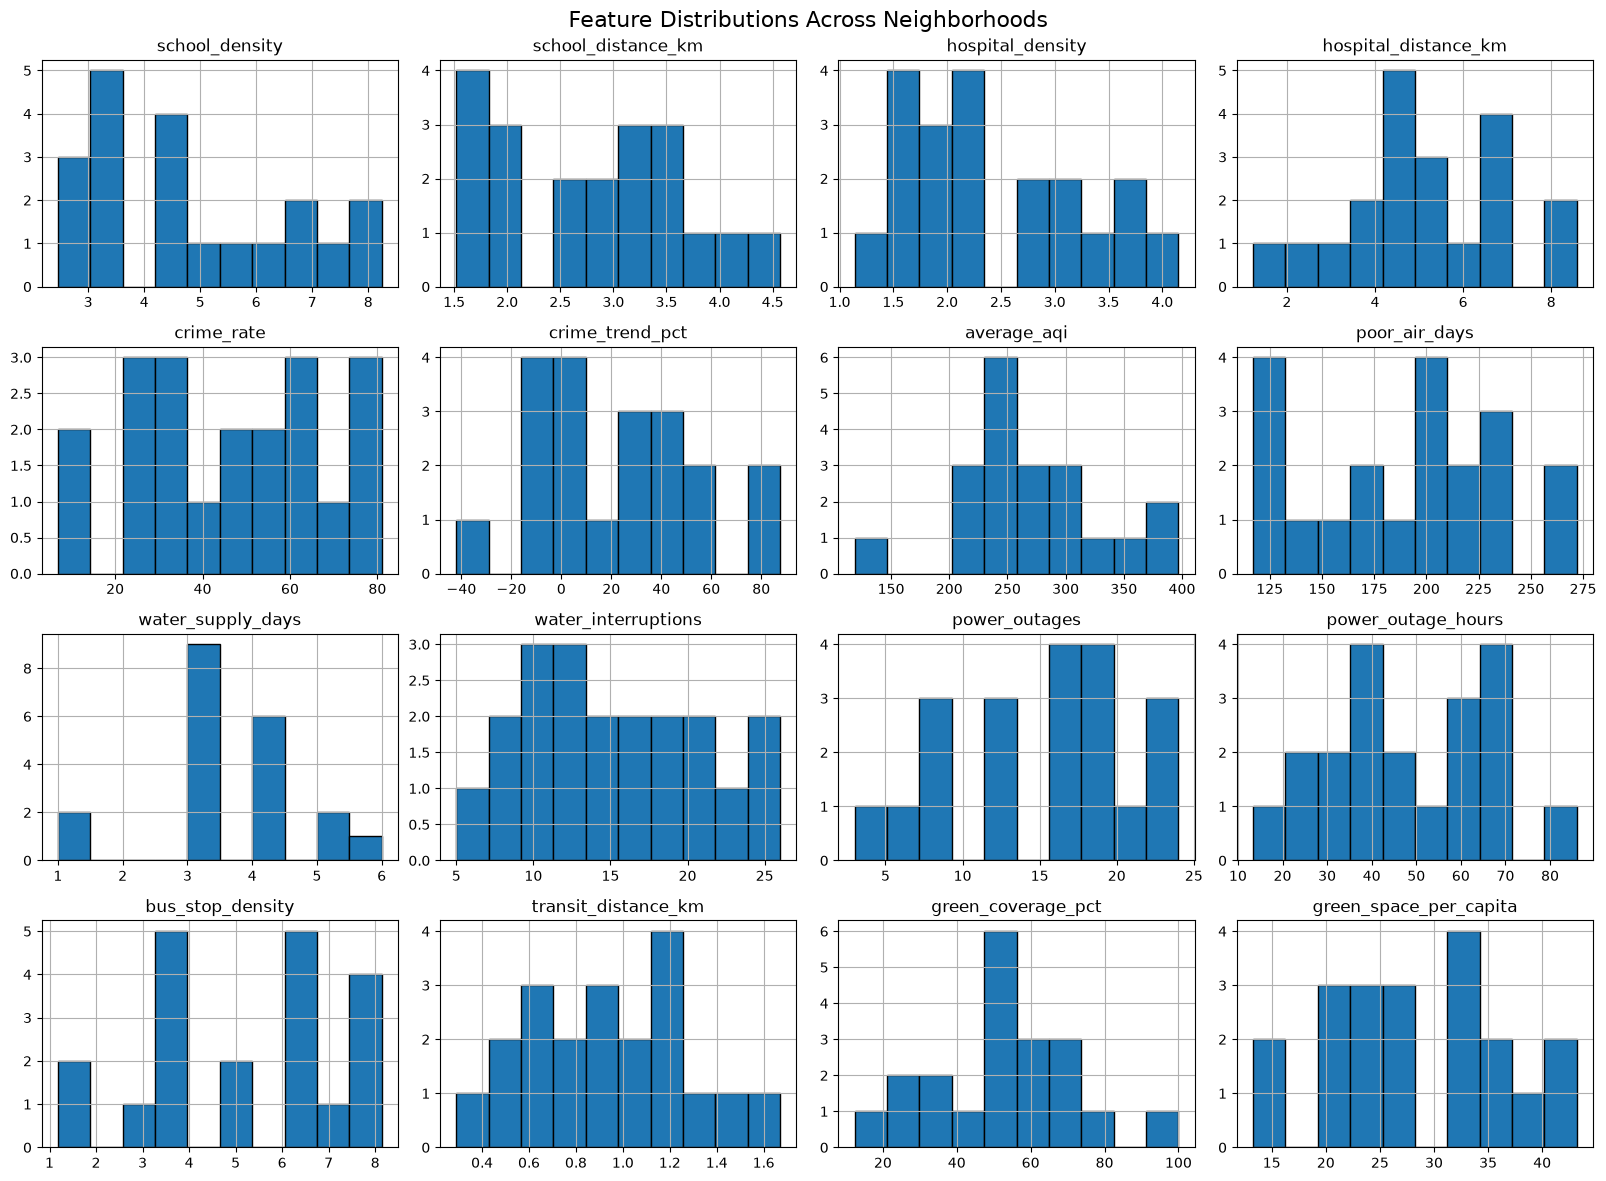

In [9]:

# Plot distributions of all 16 features

feature_columns = list(FEATURE_CONFIG.keys())

df[feature_columns].hist(
    figsize=(16, 12),
    bins=10,
    edgecolor="black"
)

plt.suptitle(
    "Feature Distributions Across Neighborhoods",
    fontsize=16
)

plt.tight_layout()
plt.show()


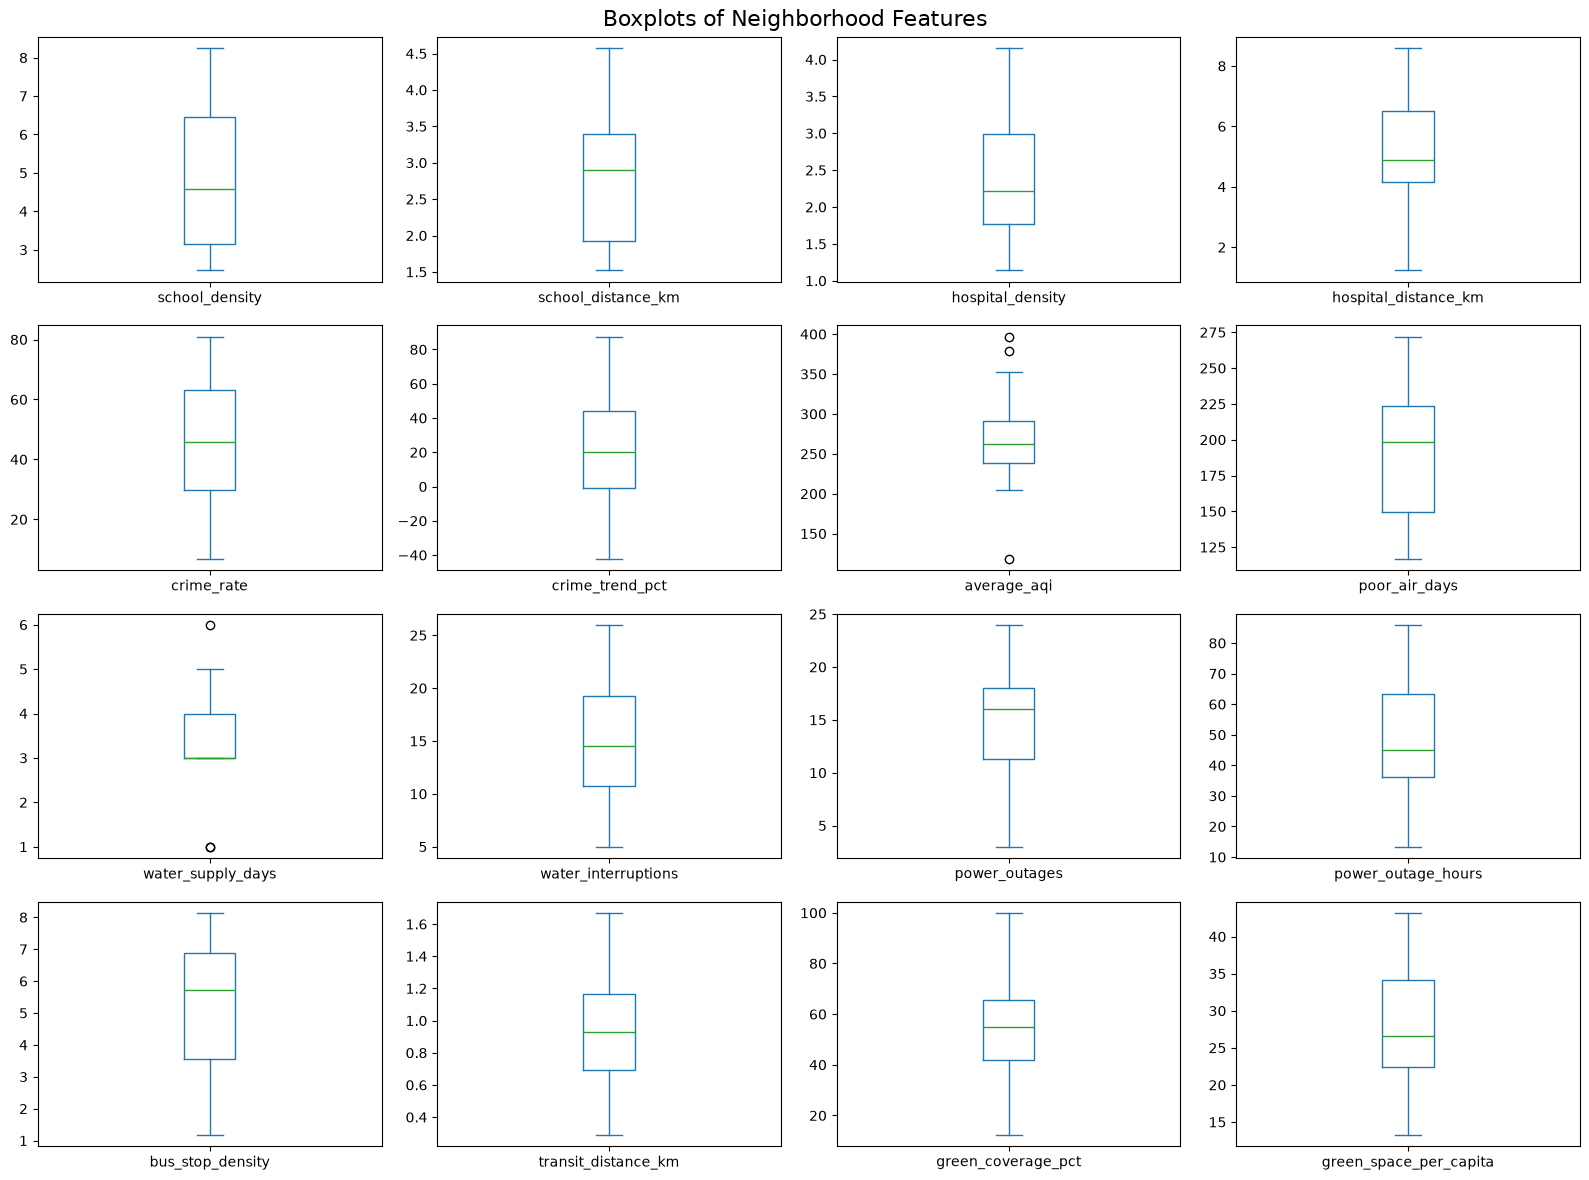

In [10]:

# Visualize feature distributions using boxplots

feature_columns = list(FEATURE_CONFIG.keys())

df[feature_columns].plot(
    kind="box",
    subplots=True,
    layout=(4, 4),
    figsize=(16, 12),
    sharex=False,
    sharey=False
)

plt.suptitle(
    "Boxplots of Neighborhood Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [11]:

# Calculate Pearson correlation between all features

feature_columns = list(FEATURE_CONFIG.keys())

correlation_matrix = df[feature_columns].corr(method="pearson")

display(correlation_matrix.round(2))


,school_density,school_distance_km,hospital_density,hospital_distance_km,crime_rate,crime_trend_pct,average_aqi,poor_air_days,water_supply_days,water_interruptions,power_outages,power_outage_hours,bus_stop_density,transit_distance_km,green_coverage_pct,green_space_per_capita
school_density,1.00,-0.89,0.38,-0.19,-0.47,-0.35,-0.24,-0.31,0.15,-0.07,-0.16,-0.23,0.30,-0.28,0.11,0.27
school_distance_km,-0.89,1.00,-0.43,0.38,0.51,0.29,0.28,0.40,-0.18,0.08,0.23,0.36,-0.50,0.37,-0.33,-0.39
hospital_density,0.38,-0.43,1.00,-0.80,-0.18,-0.07,0.15,0.21,-0.08,-0.07,-0.19,-0.31,0.23,0.04,0.45,0.29
hospital_distance_km,-0.19,0.38,-0.80,1.00,0.13,0.06,0.06,-0.14,0.17,0.06,0.00,0.21,-0.35,0.02,-0.66,-0.47
crime_rate,-0.47,0.51,-0.18,0.13,1.00,0.82,0.37,0.54,-0.53,0.56,0.55,0.55,-0.34,0.42,-0.26,-0.34
crime_trend_pct,-0.35,0.29,-0.07,0.06,0.82,1.00,0.10,0.21,-0.51,0.62,0.38,0.41,-0.30,0.33,-0.10,-0.30
average_aqi,-0.24,0.28,0.15,0.06,0.37,0.10,1.00,0.80,-0.17,0.13,-0.10,-0.01,-0.24,0.36,-0.21,-0.09
poor_air_days,-0.31,0.40,0.21,-0.14,0.54,0.21,0.80,1.00,-0.46,0.27,0.12,0.18,-0.09,0.27,-0.10,-0.10
water_supply_days,0.15,-0.18,-0.08,0.17,-0.53,-0.51,-0.17,-0.46,1.00,-0.82,-0.11,-0.22,0.19,-0.24,0.30,0.40
water_interruptions,-0.07,0.08,-0.07,0.06,0.56,0.62,0.13,0.27,-0.82,1.00,0.24,0.35,-0.15,0.17,-0.50,-0.62


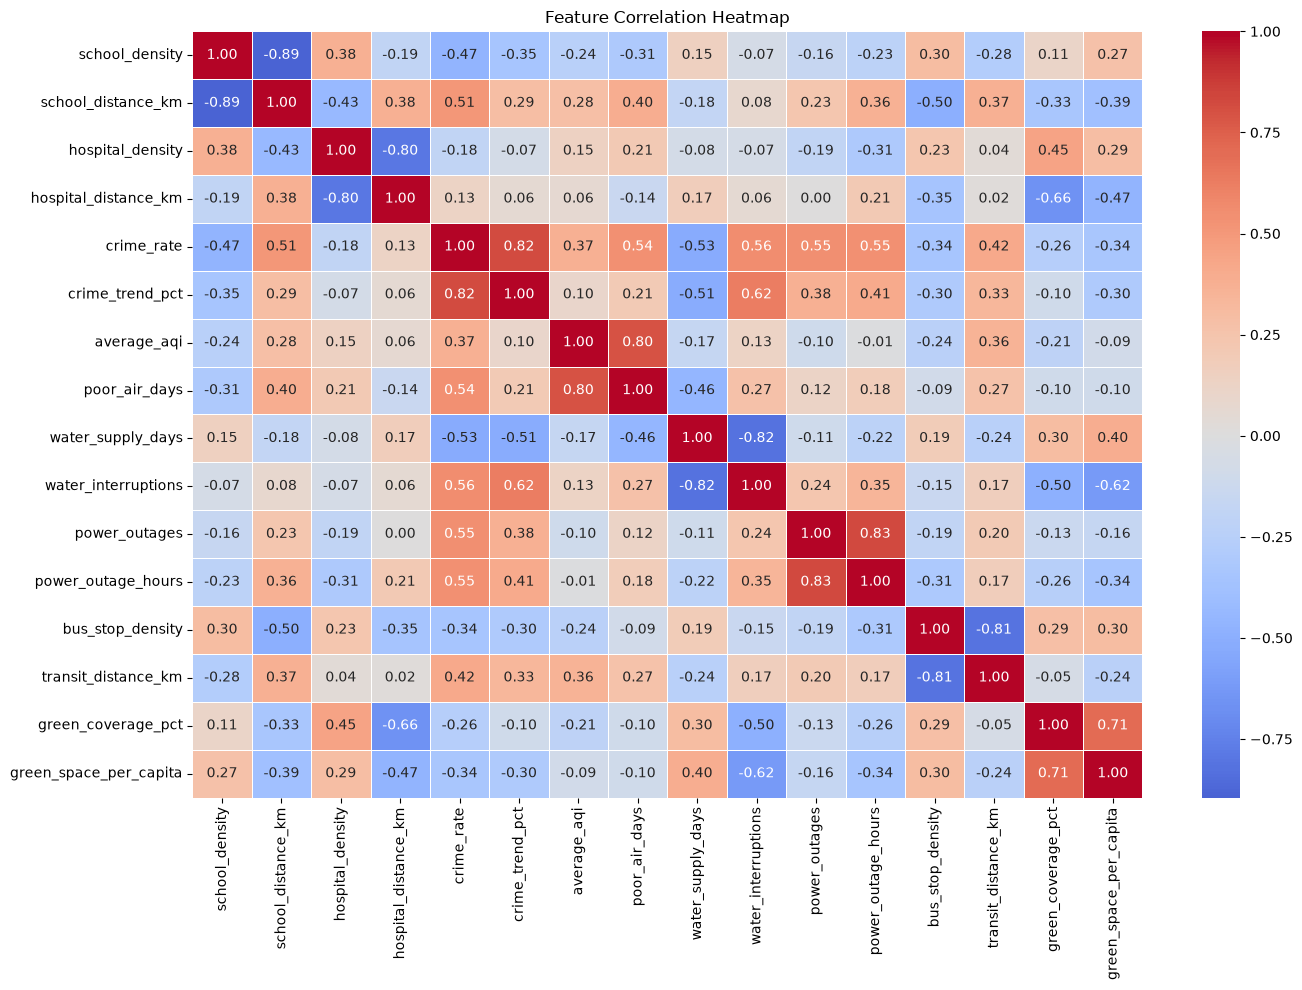

In [12]:

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [13]:

# Extract unique feature pairs and their correlations

correlation_pairs = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
).stack().reset_index()

correlation_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

correlation_pairs["Absolute Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

strongest_correlations = correlation_pairs.sort_values(
    by="Absolute Correlation",
    ascending=False
)

display(strongest_correlations.head(10).round(2))


,Feature 1,Feature 2,Correlation,Absolute Correlation
1,school_density,school_distance_km,-0.89,0.89
171,power_outages,power_outage_hours,0.83,0.83
137,water_supply_days,water_interruptions,-0.82,0.82
69,crime_rate,crime_trend_pct,0.82,0.82
205,bus_stop_density,transit_distance_km,-0.81,0.81
35,hospital_density,hospital_distance_km,-0.80,0.80
103,average_aqi,poor_air_days,0.80,0.80
239,green_coverage_pct,green_space_per_capita,0.71,0.71
62,hospital_distance_km,green_coverage_pct,-0.66,0.66
89,crime_trend_pct,water_interruptions,0.62,0.62


**2. Scoring Methodology and Implementation**

2.1 Feature Normalization

Explain that features have different units and ranges, so we convert them into a common 0–100 scale.

In [14]:
def normalize_dataset(data, feature_config):

    normalized_data = data.copy()

    for feature, config in feature_config.items():

        minimum = config["min"]
        maximum = config["max"]
        direction = config["direction"]

        if maximum <= minimum:
            raise ValueError(
                f"Invalid normalization range: {feature}"
            )

        values = data[feature]

        if values.isnull().any():
            raise ValueError(
                f"Missing values found in {feature}"
            )

        if ((values < minimum) | (values > maximum)).any():
            raise ValueError(
                f"Values outside configured bounds: {feature}"
            )

        if direction == "higher":

            score = (
                (values - minimum) /
                (maximum - minimum)
            ) * 100

        elif direction == "lower":

            score = (
                (maximum - values) /
                (maximum - minimum)
            ) * 100

        else:
            raise ValueError(
                f"Invalid direction: {feature}"
            )

        normalized_data[feature + "_normalized"] = (
            score.round(2)
        )

    return normalized_data


normalized_df = normalize_dataset(
    df,
    FEATURE_CONFIG
)

display(normalized_df.head())

,neighborhood_id,neighborhood_name,assessment_period,data_source,school_density,school_distance_km,hospital_density,hospital_distance_km,crime_rate,crime_trend_pct,...,average_aqi_normalized,poor_air_days_normalized,water_supply_days_normalized,water_interruptions_normalized,power_outages_normalized,power_outage_hours_normalized,bus_stop_density_normalized,transit_distance_km_normalized,green_coverage_pct_normalized,green_space_per_capita_normalized
0,NBH_001,Locality_01,2025,Synthetic,3.36,2.97,2.28,3.19,73.99,48.17,...,42.85,44.66,42.86,53.33,40.00,61.92,49.4,24.0,75.87,81.34
1,NBH_002,Locality_02,2025,Synthetic,8.24,1.52,1.74,6.49,32.96,0.72,...,59.08,64.11,71.43,73.33,46.67,37.66,62.1,72.0,64.85,75.62
2,NBH_003,Locality_03,2025,Synthetic,4.37,2.73,1.78,5.52,39.12,4.19,...,54.33,58.36,57.14,56.67,60.00,77.52,81.1,85.5,37.16,66.22
3,NBH_004,Locality_04,2025,Synthetic,5.60,2.83,2.95,4.84,36.10,-9.76,...,20.61,26.58,42.86,60.00,73.33,56.84,37.5,37.5,55.73,74.26
4,NBH_005,Locality_05,2025,Synthetic,6.92,1.93,3.59,4.04,57.59,48.87,...,45.52,38.08,14.29,16.67,60.00,66.80,62.1,42.5,43.28,26.54


### 2.2 Category Score Aggregation

Normalized feature scores are grouped into their respective categories.

Each category score is calculated as the arithmetic mean of its normalized feature scores.

In [15]:
def aggregate_categories(data, feature_config):

    category_scores = data[
        ["neighborhood_id", "neighborhood_name"]
    ].copy()

    categories = sorted(set(
        config["category"]
        for config in feature_config.values()
    ))

    for category in categories:

        category_features = [
            feature
            for feature, config in feature_config.items()
            if config["category"] == category
        ]

        normalized_columns = [
            feature + "_normalized"
            for feature in category_features
        ]

        category_scores[category + "_score"] = (
            data[normalized_columns]
            .mean(axis=1)
            .round(2)
        )

    return category_scores


category_df = aggregate_categories(
    normalized_df,
    FEATURE_CONFIG
)

display(category_df.head())

,neighborhood_id,neighborhood_name,Air Quality_score,Education_score,Electricity_score,Green Space_score,Healthcare_score,Safety_score,Transport_score,Water_score
0,NBH_001,Locality_01,43.76,37.10,50.96,78.60,56.85,30.28,36.70,48.10
1,NBH_002,Locality_02,61.60,76.00,42.16,70.24,34.95,66.62,67.05,72.38
2,NBH_003,Locality_03,56.34,44.55,68.76,51.69,40.20,62.38,83.30,56.90
3,NBH_004,Locality_04,23.60,49.70,65.09,65.00,55.30,68.54,37.50,51.43
4,NBH_005,Locality_05,41.80,65.30,63.40,34.91,65.70,38.25,52.30,15.48


### 2.3 Overall Score and Neighborhood Ranking

The overall neighborhood score is calculated as the arithmetic mean of the eight category scores.


In [16]:
def calculate_overall_score(category_data):

    overall_scores = category_data.copy()

    category_columns = [
        col for col in overall_scores.columns
        if col.endswith("_score")
    ]

    overall_scores["overall_score"] = (
        overall_scores[category_columns]
        .mean(axis=1)
        .round(2)
    )

    overall_scores["rank"] = (
        overall_scores["overall_score"]
        .rank(method="min", ascending=False)
        .astype(int)
    )

    overall_scores = overall_scores.sort_values(
        by="overall_score",
        ascending=False
    ).reset_index(drop=True)

    return overall_scores


final_scores_df = calculate_overall_score(category_df)

display(final_scores_df)

,neighborhood_id,neighborhood_name,Air Quality_score,Education_score,Electricity_score,Green Space_score,Healthcare_score,Safety_score,Transport_score,Water_score,overall_score,rank
0,NBH_012,Locality_12,70.74,69.95,51.28,93.20,80.75,85.02,53.40,63.57,70.99,1
1,NBH_010,Locality_10,55.55,67.05,88.31,58.36,53.60,91.88,73.20,69.05,69.62,2
2,NBH_002,Locality_02,61.60,76.00,42.16,70.24,34.95,66.62,67.05,72.38,61.38,3
3,NBH_013,Locality_13,49.87,48.05,59.84,63.42,57.75,68.54,76.65,61.90,60.75,4
4,NBH_003,Locality_03,56.34,44.55,68.76,51.69,40.20,62.38,83.30,56.90,58.02,5
5,NBH_018,Locality_18,47.76,29.80,48.40,60.38,55.70,73.27,57.50,84.52,57.17,6
6,NBH_009,Locality_09,47.54,52.00,68.97,66.52,36.30,60.20,67.30,44.76,55.45,7
7,NBH_004,Locality_04,23.60,49.70,65.09,65.00,55.30,68.54,37.50,51.43,52.02,8
8,NBH_008,Locality_08,44.86,39.80,44.38,52.84,49.00,54.60,70.50,44.76,50.09,9
9,NBH_020,Locality_20,24.80,26.40,74.40,59.80,64.65,59.49,39.05,49.76,49.79,10


### 2.4 Scoring Validation

This stage verifies the correctness and consistency of the generated category scores, overall scores and neighborhood rankings.
    
-> It checks score boundaries, missing values, duplicate ranks and ranking order to ensure the scoring pipeline produces valid results.

In [17]:
category_columns = [
    col for col in final_scores_df.columns
    if col.endswith("_score") and col != "overall_score"
]

score_columns = category_columns + ["overall_score"]

print("SCORING VALIDATION REPORT")
print("-------------------------")

print(
    "Scores within 0-100:",
    final_scores_df[score_columns]
    .ge(0).all().all()
    and final_scores_df[score_columns].le(100).all().all()
)

print(
    "Missing scores:",
    final_scores_df[score_columns].isnull().sum().sum()
)

print(
    "Duplicate ranks:",
    final_scores_df["rank"].duplicated().sum()
)

print(
    "Ranking order correct:",
    final_scores_df["overall_score"].is_monotonic_decreasing
)

print(
    "Total neighborhoods:",
    len(final_scores_df)
)

SCORING VALIDATION REPORT
-------------------------
Scores within 0-100: True
Missing scores: 0
Duplicate ranks: 0
Ranking order correct: True
Total neighborhoods: 20


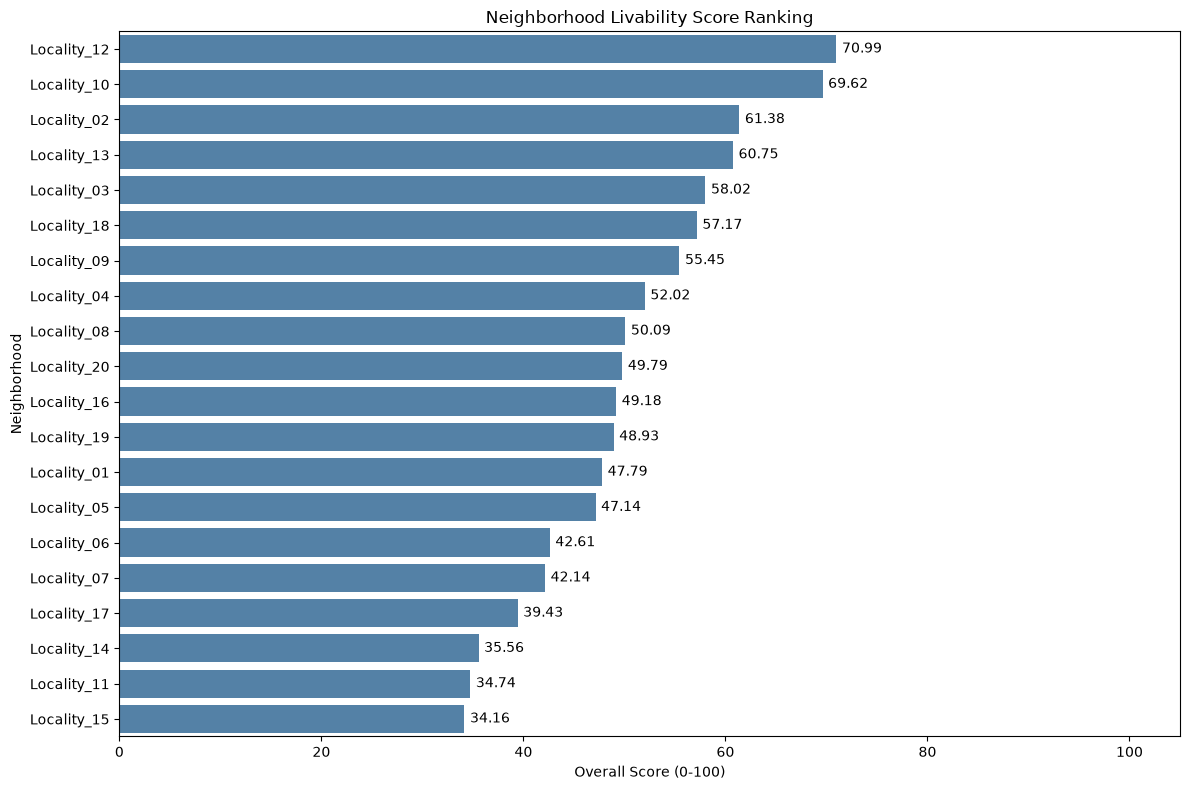

In [18]:
# 2.5 Neighborhood Livability Leaderboard

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=final_scores_df,
    x="overall_score",
    y="neighborhood_name",
    color="steelblue"
)

ax.bar_label(ax.containers[0], fmt="%.2f", padding=4)

plt.title("Neighborhood Livability Score Ranking")
plt.xlabel("Overall Score (0-100)")
plt.ylabel("Neighborhood")
plt.xlim(0, 105)

plt.tight_layout()

plt.savefig("screenshots/Neighborhood_Livability_Leaderboard_v0.2.png",
            dpi=300, bbox_inches="tight")

plt.show()

## 3. Scoring Analysis and Methodological Limitations

### 3.1 Category Performance Analysis

The category-level results across 20 synthetic neighborhoods are summarized below.

| Category | Mean | Standard Deviation |
|---|---:|---:|
| Electricity | 55.93 | 15.14 |
| Transport | 55.84 | 17.65 |
| Water | 55.02 | 17.83 |
| Green Space | 53.78 | 19.09 |
| Education | 53.02 | 17.14 |
| Safety | 53.01 | 19.87 |
| Air Quality | 53.00 | 19.46 |
| Healthcare | 46.06 | 19.74 |

Electricity recorded the highest average score, while Healthcare recorded the lowest. Safety showed the greatest variation between neighborhoods.

### 3.2 Overall Score Distribution

| Metric | Value |
|---|---:|
| Number of neighborhoods | 20 |
| Mean | 53.21 |
| Median | 50.40 |
| Standard deviation | 11.27 |
| Minimum | 33.68 |
| Maximum | 76.62 |

The results demonstrate that the composite scoring model differentiates neighborhoods according to their generated feature values.

### 3.3 Methodological Limitations

The current scoring methodology has the following limitations:

1. **Equal Weighting:** All features within categories and all categories within the overall score receive equal weights. This assumes equal importance, which has not yet been empirically established.

2. **Feature Correlation:** Highly correlated features may represent overlapping information and contribute to double counting during score aggregation.

3. **Linear Normalization:** The normalization method assumes a linear relationship between feature values and their corresponding scores. Real-world livability relationships may be nonlinear or threshold-dependent.

4. **Synthetic Data:** The generated dataset is intended for development and testing. Its statistical relationships and scoring results cannot establish actual neighborhood conditions or predictive accuracy.

### 3.4 Conclusion

The v0.2 scoring pipeline successfully implements feature normalization, category aggregation, overall score calculation, neighborhood ranking and validation.

The current methodology provides a transparent baseline for neighborhood comparison. Further improvements will require real-world data, better-established scoring benchmarks, and evaluation of feature weighting and relationships.

**Dataset status:** Synthetic — not representative of measured neighborhood conditions.

In [19]:
# Export processed datasets and final neighborhood rankings.

df.to_csv("nis_v02_synthetic_data.csv", index=False)

normalized_df.to_csv(
    "nis_v02_normalized_data.csv",
    index=False
)

final_scores_df.to_csv(
    "nis_v02_neighborhood_rankings.csv",
    index=False
)

In [20]:
import os

export_files = [
    "nis_v02_synthetic_data.csv",
    "nis_v02_normalized_data.csv",
    "nis_v02_neighborhood_rankings.csv"
]

for file in export_files:
    print(f"{file}: {'Created' if os.path.exists(file) else 'Missing'}")

nis_v02_synthetic_data.csv: Created
nis_v02_normalized_data.csv: Created
nis_v02_neighborhood_rankings.csv: Created


In [21]:
print(os.getcwd())

C:\Users\Rehaan\Desktop\neighborhood-intelligence-system
